In [1]:
import geopandas as gd

In [2]:
import pandas as pd

In [5]:
df_geomunicipios = gd.read_file("../data/raw/MGMPIGRAFICO/MGN_ADM_MPIO_GRAFICO.shp")

In [4]:
!pwd

/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/Notebooks


In [8]:
import matplotlib as mp

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

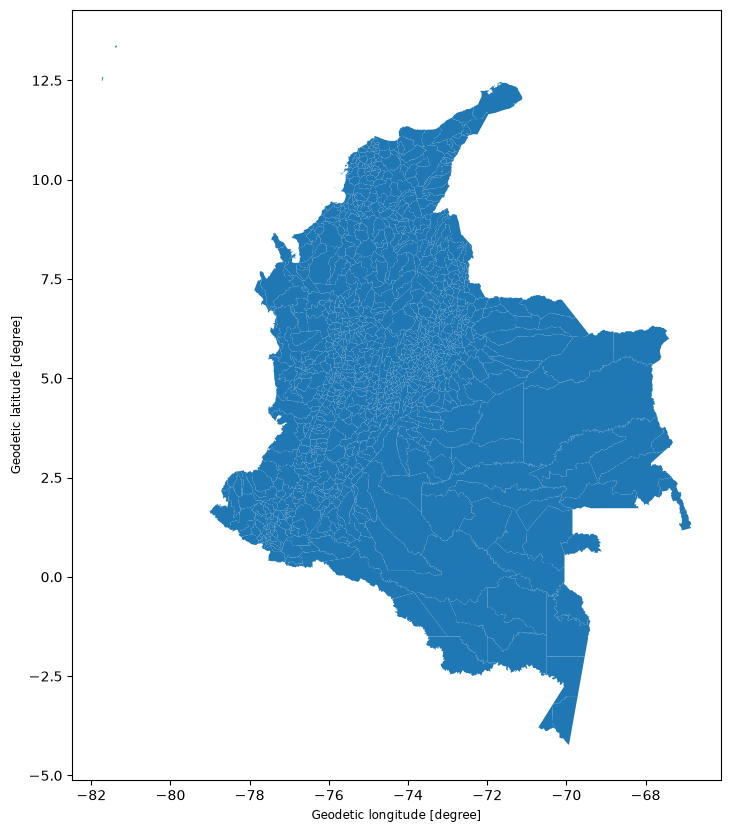

In [10]:
df_geomunicipios.plot(figsize = (10,10)) 

In [11]:
df_geomunicipios.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1122 entries, 0 to 1121
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   dpto_ccdgo  1122 non-null   object  
 1   mpio_ccdgo  1122 non-null   object  
 2   mpio_cdpmp  1122 non-null   object  
 3   dpto_cnmbr  1122 non-null   object  
 4   mpio_cnmbr  1122 non-null   object  
 5   mpio_crslc  1122 non-null   object  
 6   mpio_tipo   1122 non-null   object  
 7   mpio_narea  1122 non-null   float64 
 8   mpio_nano   1122 non-null   int32   
 9   shape_Leng  1122 non-null   float64 
 10  shape_Area  1122 non-null   float64 
 11  geometry    1122 non-null   geometry
dtypes: float64(3), geometry(1), int32(1), object(7)
memory usage: 100.9+ KB


In [16]:
df_geomunicipios["geometry"].head(5)

0    POLYGON ((-75.4857 6.20163, -75.48567 6.20148,...
1    POLYGON ((-75.46938 5.94575, -75.46897 5.94571...
2    POLYGON ((-76.09047 6.74542, -76.09066 6.74548...
3    POLYGON ((-75.0332 6.41586, -75.03313 6.41585,...
4    POLYGON ((-75.67587 6.08561, -75.6754 6.08491,...
Name: geometry, dtype: geometry

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

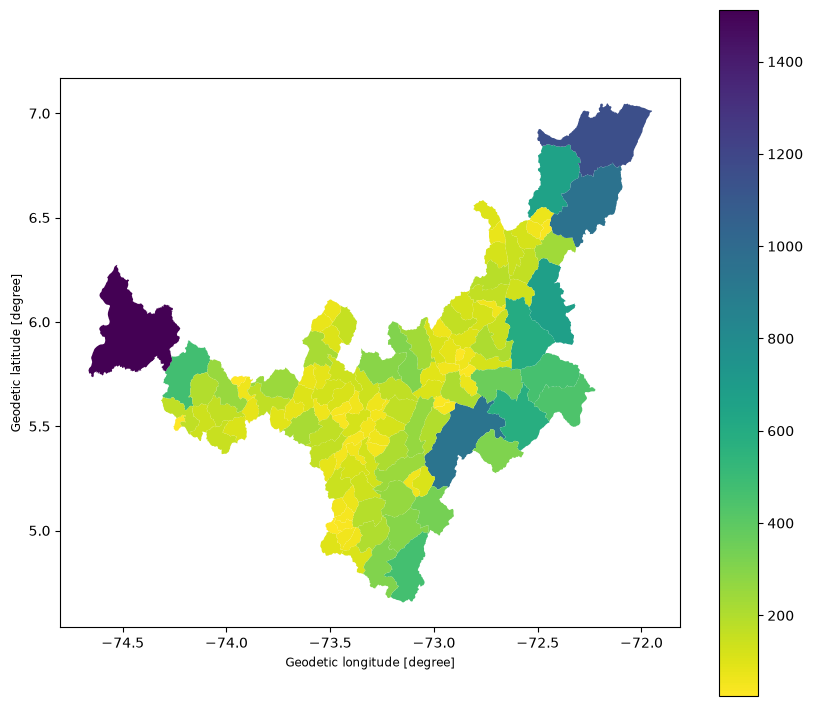

In [25]:
municipios_boyaca = df_geomunicipios[df_geomunicipios['dpto_cnmbr'] == 'BOYACÁ']
municipios_boyaca.plot(figsize=(10,10), cmap= "viridis_r", column="mpio_narea", legend=True)

In [31]:
chiq = df_geomunicipios[df_geomunicipios['mpio_cnmbr']=='CHIQUINQUIRÁ']
result = gd.sjoin(chiq, municipios_boyaca, how='inner', predicate="within")
display(result)

,dpto_ccdgo_left,mpio_ccdgo_left,mpio_cdpmp_left,dpto_cnmbr_left,mpio_cnmbr_left,mpio_crslc_left,mpio_tipo_left,mpio_narea_left,mpio_nano_left,shape_Leng_left,...,mpio_ccdgo_right,mpio_cdpmp_right,dpto_cnmbr_right,mpio_cnmbr_right,mpio_crslc_right,mpio_tipo_right,mpio_narea_right,mpio_nano_right,shape_Leng_right,shape_Area_right
211,15,176,15176,BOYACÁ,CHIQUINQUIRÁ,1776,MUNICIPIO,164.778385,2024,0.864134,...,176,15176,BOYACÁ,CHIQUINQUIRÁ,1776,MUNICIPIO,164.778385,2024,0.864134,0.013469


In [36]:
df_divipola = pd.read_csv("../data/raw/divipola.csv")
df_eva = pd.read_csv("../data/raw/eva.csv")

In [105]:
df_divipola.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1122 entries, 0 to 1121
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype 
---  ------                                           --------------  ----- 
 0   Código Departamento                              1122 non-null   int64 
 1   Nombre Departamento                              1122 non-null   object
 2   Código Municipio                                 1122 non-null   int64 
 3   Nombre Municipio                                 1122 non-null   object
 4   Tipo: Municipio / Isla / Área no municipalizada  1122 non-null   object
 5   longitud                                         1122 non-null   object
 6   Latitud                                          1122 non-null   object
dtypes: int64(2), object(5)
memory usage: 61.5+ KB


In [37]:
df_divipola.head(5)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,5,ANTIOQUIA,5001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,5,ANTIOQUIA,5002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,5,ANTIOQUIA,5004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,5,ANTIOQUIA,5021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,5,ANTIOQUIA,5030,AMAGÁ,Municipio,"-75,702188","6,038708"


In [38]:
df_eva.head(5)

,Código Dane departamento,Departamento,Código Dane municipio,Municipio,Grupo cultivo,Subgrupo,Cultivo,Desagregación cultivo,Año,Periodo,Área sembrada,Área cosechada,Producción,Rendimiento,Ciclo del cultivo,Estado físico del cultivo,Código del cultivo,Nombre científico del cultivo
0,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2021,2021A,8.0,8.0,128.00,16.00,Transitorio,En fresco,1050600,Apium graveolens
1,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2021,2021B,8.0,8.0,152.00,19.00,Transitorio,En fresco,1050600,Apium graveolens
2,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2022,2022A,8.0,8.0,127.44,15.93,Transitorio,En fresco,1050600,Apium graveolens
3,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2022,2022B,8.0,8.0,152.00,19.00,Transitorio,En fresco,1050600,Apium graveolens
4,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2023,2023A,8.0,7.0,133.00,19.00,Transitorio,En fresco,1050600,Apium graveolens


In [43]:
# Extraer códigos únicos de departamento y ordenarlos
codigos_departamento = df_divipola["Código Departamento"].sort_values().unique()

print("Total departamentos:", len(codigos_departamento))
print("Códigos únicos:", codigos_departamento)

Total departamentos: 33
Códigos únicos: [ 5  8 11 13 15 17 18 19 20 23 25 27 41 44 47 50 52 54 63 66 68 70 73 76
 81 85 86 88 91 94 95 97 99]


In [50]:
# Otra forma -> Extraer códigos únicos de departamento y ordenarlos
dep_divipola = df_divipola.sort_values(by=["Código Departamento"], ascending=True)["Código Departamento"]
print(dep_divipola.unique())

[ 5  8 11 13 15 17 18 19 20 23 25 27 41 44 47 50 52 54 63 66 68 70 73 76
 81 85 86 88 91 94 95 97 99]


In [56]:
dep_divipola.info()

<class 'pandas.core.series.Series'>
Index: 1122 entries, 32 to 1121
Series name: Código Departamento
Non-Null Count  Dtype
--------------  -----
1122 non-null   int64
dtypes: int64(1)
memory usage: 17.5 KB


In [54]:
dep_dane = df_geomunicipios.sort_values(by=["dpto_ccdgo"], ascending = True) ["dpto_ccdgo"]
print(dep_dane.unique())

['05' '08' '11' '13' '15' '17' '18' '19' '20' '23' '25' '27' '41' '44'
 '47' '50' '52' '54' '63' '66' '68' '70' '73' '76' '81' '85' '86' '88'
 '91' '94' '95' '97' '99']


In [55]:
dep_dane.info()

<class 'pandas.core.series.Series'>
Index: 1122 entries, 0 to 1121
Series name: dpto_ccdgo
Non-Null Count  Dtype 
--------------  ----- 
1122 non-null   object
dtypes: object(1)
memory usage: 17.5+ KB


In [59]:
depart_dane = dep_dane.astype(int)

In [60]:
depart_dane.info()

<class 'pandas.core.series.Series'>
Index: 1122 entries, 0 to 1121
Series name: dpto_ccdgo
Non-Null Count  Dtype
--------------  -----
1122 non-null   int64
dtypes: int64(1)
memory usage: 17.5 KB


In [62]:
dep_divipola.count()

np.int64(1122)

In [63]:
depart_dane.count()

np.int64(1122)

In [70]:
len(dep_divipola.unique())

33

In [71]:
len(depart_dane.unique())

33

In [72]:
df_eva.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166732 entries, 0 to 166731
Data columns (total 18 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Código Dane departamento       166732 non-null  int64  
 1   Departamento                   166732 non-null  object 
 2   Código Dane municipio          166732 non-null  int64  
 3   Municipio                      166732 non-null  object 
 4   Grupo cultivo                  166732 non-null  object 
 5   Subgrupo                       166732 non-null  object 
 6   Cultivo                        166732 non-null  object 
 7   Desagregación cultivo          166732 non-null  object 
 8   Año                            166732 non-null  int64  
 9   Periodo                        166732 non-null  object 
 10  Área sembrada                  166732 non-null  float64
 11  Área cosechada                 166732 non-null  float64
 12  Producción                    

In [144]:
df_geomunicipios.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1122 entries, 0 to 1121
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   dpto_ccdgo  1122 non-null   object  
 1   mpio_ccdgo  1122 non-null   object  
 2   mpio_cdpmp  1122 non-null   object  
 3   dpto_cnmbr  1122 non-null   object  
 4   mpio_cnmbr  1122 non-null   object  
 5   mpio_crslc  1122 non-null   object  
 6   mpio_tipo   1122 non-null   object  
 7   mpio_narea  1122 non-null   float64 
 8   mpio_nano   1122 non-null   int32   
 9   shape_Leng  1122 non-null   float64 
 10  shape_Area  1122 non-null   float64 
 11  geometry    1122 non-null   geometry
dtypes: float64(3), geometry(1), int32(1), object(7)
memory usage: 100.9+ KB


In [73]:
dep_eva = df_eva.sort_values(by=["Código Dane departamento"], ascending = True) ["Código Dane departamento"]

In [74]:
dep_eva.unique()

array([ 5,  8, 13, 15, 17, 18, 19, 20, 23, 25, 27, 41, 44, 47, 50, 52, 54,
       63, 66, 68, 70, 73, 76, 81, 85, 86, 88, 91, 94, 95, 97, 99])

In [75]:
len(dep_eva.unique())

32

In [83]:
validar_df = pd.merge(left=dep_eva, right=dep_divipola, how='left', left_on=["Código Dane departamento"], right_on=["Código Departamento"], indicator=True)

In [84]:
display(validar_df)

,Código Dane departamento,Código Departamento,_merge
0,5,5,both
1,5,5,both
2,5,5,both
3,5,5,both
4,5,5,both
...,...,...,...
10825541,99,99,both
10825542,99,99,both
10825543,99,99,both
10825544,99,99,both


In [87]:
validar_df [validar_df["_merge"]!="both"]

,Código Dane departamento,Código Departamento,_merge


In [86]:
import numpy as np

In [92]:
display(dep_divipola.unique())
print('----------------------')
display(dep_eva.unique())

array([ 5,  8, 11, 13, 15, 17, 18, 19, 20, 23, 25, 27, 41, 44, 47, 50, 52,
       54, 63, 66, 68, 70, 73, 76, 81, 85, 86, 88, 91, 94, 95, 97, 99])

----------------------


array([ 5,  8, 13, 15, 17, 18, 19, 20, 23, 25, 27, 41, 44, 47, 50, 52, 54,
       63, 66, 68, 70, 73, 76, 81, 85, 86, 88, 91, 94, 95, 97, 99])

In [91]:
res = np.nonzero(np.isin(dep_eva.unique(), dep_divipola.unique()))[0]
display(res)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [101]:
a = pd.Series(dep_eva.unique())

In [96]:
b = pd.Series(dep_divipola.unique())

In [103]:
# Compara cual es el dato distinto de una serie contra otra
display(b[~b.isin(a)])

2    11
dtype: int64

In [104]:
df_divipola[~df_divipola['Código Departamento'].isin(df_eva['Código Dane departamento'])]

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
148,11,"BOGOTÁ, D.C.",11001,"BOGOTÁ, D.C.",Municipio,"-74,106992","4,649251"


In [ ]:
# GUIA para hacer JOIN en python
import pandas as pd

# 1. En A pero no en B
caso_1 = df_A[~df_A['cedula'].isin(df_B['cedula'])]

# 2. En B pero no en A
caso_2 = df_B[~df_B['cedula'].isin(df_A['cedula'])]

# 3. Todo B (incluyendo la intersección con A)
caso_3 = df_B.copy()
# O si requieres traer columnas de A hacia B:
caso_3_con_datos_A = pd.merge(df_B, df_A, on='cedula', how='left')

# 4. Intersección (presentes en ambos)
caso_4 = pd.merge(df_A, df_B, on='cedula', how='inner')

In [128]:
df_eva.head(5)

,Código Dane departamento,Departamento,Código Dane municipio,Municipio,Grupo cultivo,Subgrupo,Cultivo,Desagregación cultivo,Año,Periodo,Área sembrada,Área cosechada,Producción,Rendimiento,Ciclo del cultivo,Estado físico del cultivo,Código del cultivo,Nombre científico del cultivo
0,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2021,2021A,8.0,8.0,128.00,16.00,Transitorio,En fresco,1050600,Apium graveolens
1,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2021,2021B,8.0,8.0,152.00,19.00,Transitorio,En fresco,1050600,Apium graveolens
2,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2022,2022A,8.0,8.0,127.44,15.93,Transitorio,En fresco,1050600,Apium graveolens
3,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2022,2022B,8.0,8.0,152.00,19.00,Transitorio,En fresco,1050600,Apium graveolens
4,5,Antioquia,5001,Medellín,Hortalizas,Hortalizas de tallo,Apio,Apio,2023,2023A,8.0,7.0,133.00,19.00,Transitorio,En fresco,1050600,Apium graveolens


In [127]:
df_divipola.head(5)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,5,ANTIOQUIA,5001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,5,ANTIOQUIA,5002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,5,ANTIOQUIA,5004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,5,ANTIOQUIA,5021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,5,ANTIOQUIA,5030,AMAGÁ,Municipio,"-75,702188","6,038708"


In [129]:
df_geomunicipios.head(5)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


In [143]:
eva_boyaca_municipios = df_eva[df_eva['Departamento']=='Boyacá'].sort_values(by=['Municipio']).drop_duplicates(subset=['Municipio'])
#print(eva_boyaca_municipios)
divipola_boyaca_municipios = df_divipola[df_divipola["Nombre Departamento"] == "BOYACÁ"].sort_values(by=["Código Municipio"]).drop_duplicates(subset=["Código Municipio"])
#print(divipola_boyaca_municipios)
dane_boyaca_municipios = df_geomunicipios[df_geomunicipios["dpto_cnmbr"] == "BOYACÁ"].sort_values(by=["mpio_ccdgo"]).drop_duplicates(subset=["mpio_ccdgo"])
#print(dane_boyaca_municipios)

merged_df_boyaca = pd.merge(
    left = divipola_boyaca_municipios,
    right = eva_boyaca_municipios,
    how='left',
    left_on=["Código Municipio"],
    right_on = ["Código Dane municipio"],
    indicator=True)

merged_gdf_boyaca = pd.merge(
    left = divipola_boyaca_municipios,
    right = dane_boyaca_municipios,
    how='left',
    left_on=["Código Municipio"],
    right_on = ["mpio_cdpmp"],
    indicator=True)

# display(merged_gdf_boyaca[merged_gdf_boyaca['_merge'] != 'both'])

ValueError: You are trying to merge on int64 and object columns for key 'Código Municipio'. If you wish to proceed you should use pd.concat